<img
  src="https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/5604_AssignmentImage.bmp"
  width="40%"
  alt="OPIM 5641 assignment banner"
/>

# Environment Setup

In [1]:
# import modules

import pandas as pd # for data viz and wrangling
import numpy as np # for 'numeric python'
import matplotlib.pyplot as plt # for data viz (more complex than pylab)
import seaborn as sns
from pylab import * # for data viz (import * means 'import all of the functions')

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn import metrics
from scipy import stats
import statsmodels.api as sm


#Load the Data - ToyotaCorolla1000

In [2]:
# read data
# on the lefthand side, navigate to your data and copy the path
data_file = 'https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/M10/ToyotaCorolla1000.csv'

df = pd.read_csv(data_file)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Number of rows: 1000
Number of columns: 10


,Price,Age,Mileage,Fuel Type,Horse Power,Metalic,Automatic,CC,Doors,Weight
0,13500,23,46986,Diesel,90,1,0,2000,3,1165
1,13750,23,72937,Diesel,90,1,0,2000,3,1165
2,13950,24,41711,Diesel,90,1,0,2000,3,1165
3,14950,26,48000,Diesel,90,0,0,2000,3,1165
4,13750,30,38500,Diesel,90,0,0,2000,3,1170


In [3]:
# shape
# shows how many rows and columns
# this sample has 1000 rows and 10 columns
df.shape

(1000, 10)

In [4]:
# Preview
print(df.head())

   Price  Age  Mileage Fuel Type  Horse Power  Metalic  Automatic    CC  \
0  13500   23    46986    Diesel           90        1          0  2000   
1  13750   23    72937    Diesel           90        1          0  2000   
2  13950   24    41711    Diesel           90        1          0  2000   
3  14950   26    48000    Diesel           90        0          0  2000   
4  13750   30    38500    Diesel           90        0          0  2000   

   Doors  Weight  
0      3    1165  
1      3    1165  
2      3    1165  
3      3    1165  
4      3    1170  


In [5]:
# Create dummy variables for 'Fuel Type'
df = pd.get_dummies(df, columns=['Fuel Type'], drop_first=True)

# Display the first few rows to see the changes
print(df.head())

   Price  Age  Mileage  Horse Power  Metalic  Automatic    CC  Doors  Weight  \
0  13500   23    46986           90        1          0  2000      3    1165   
1  13750   23    72937           90        1          0  2000      3    1165   
2  13950   24    41711           90        1          0  2000      3    1165   
3  14950   26    48000           90        0          0  2000      3    1165   
4  13750   30    38500           90        0          0  2000      3    1170   

   Fuel Type_Diesel  Fuel Type_Petrol  
0              True             False  
1              True             False  
2              True             False  
3              True             False  
4              True             False  


Before we model, we need to partition the data.

In [6]:
from sklearn.model_selection import train_test_split

# Define the target variable
target = 'Price'
features = df.drop(target, axis=1)
target_variable = df[target]

# Split the data into 80% training and 20% test
X_train, X_test, y_train, y_test = train_test_split(features, target_variable, test_size=0.2, random_state=42)

# Split the 80% training data into 50% training and 30% validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.375, random_state=42) # 0.375 * 0.8 = 0.3

# Print the shapes of the resulting datasets
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (500, 10) (500,)
Validation set shape: (300, 10) (300,)
Test set shape: (200, 10) (200,)


#Neural Network

Let's build a neural network model.  First we standardize the predictors then we fit the model.

In [7]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error # Import mean_squared_error to calculate MSE first

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


# Build the neural network model
nn_model = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=2000, random_state=42, learning_rate_init=0.01)

# Train the model
nn_model.fit(X_train_scaled, y_train)

# Make predictions on the validation set
y_pred_val = nn_model.predict(X_val_scaled)

# Evaluate the model
mse = mean_squared_error(y_val, y_pred_val)
rmse = np.sqrt(mse) # Calculate RMSE
r2 = r2_score(y_val, y_pred_val)

print(f"Root Mean Squared Error on validation set: {rmse}") # Print RMSE
print(f"R-squared on validation set: {r2}")

Root Mean Squared Error on validation set: 1236.0715280047311
R-squared on validation set: 0.8957169275847072


Interpretation:
1. The R-squared value of 0.8957 indicates that the model explains approximately 89.57% of the variation in car prices using the available predictors.
2. The RMSE of 1,236.07 means that the model's predictions typically have an error of approximately 1,236 price units.
3. Overall, the model demonstrates strong predictive performance on the validation dataset.

The model performs well in predicting car prices, with an R-squared of approximately 0.90, indicating that it explains nearly 90% of the variation in prices. The RMSE of 1,236 suggests that the average prediction error is relatively small compared with the car prices in the dataset. Overall, the results indicate that the selected features provide useful information for predicting car prices.

Now lets check its performance on each partition.

In [8]:
from sklearn.metrics import mean_squared_error, r2_score

# Make predictions on all three sets
y_pred_train = nn_model.predict(X_train_scaled)
y_pred_val = nn_model.predict(X_val_scaled)
y_pred_test = nn_model.predict(X_test_scaled)

# Evaluate performance on the training set
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# Evaluate performance on the validation set
rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2_val = r2_score(y_val, y_pred_val)

# Evaluate performance on the test set
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

# Print the results
print("Neural Network Model Performance:")
print(f"  Training Set: RMSE = {rmse_train:.2f}, R-squared = {r2_train:.2f}")
print(f"  Validation Set: RMSE = {rmse_val:.2f}, R-squared = {r2_val:.2f}")
print(f"  Test Set: RMSE = {rmse_test:.2f}, R-squared = {r2_test:.2f}")

Neural Network Model Performance:
  Training Set: RMSE = 1021.70, R-squared = 0.93
  Validation Set: RMSE = 1236.07, R-squared = 0.90
  Test Set: RMSE = 1750.17, R-squared = 0.71


Observations:
1. Training performance: The model achieved an R-squared of 0.93, explaining 93% of the variation in car prices.
2. Validation performance: The R-squared of 0.90 indicates strong predictive performance on unseen validation data.
3. Test performance: The R-squared dropped to 0.71, while RMSE increased to 1,750.17. This suggests that the model's predictions are less accurate on the test dataset.
4. Overfitting: The difference between training and test performance suggests some overfitting. The model performs well on training and validation data but does not generalize as effectively to the test data.

Training and validation look good.  But Test does not.  Let's look at the residuals to see what is happening.  

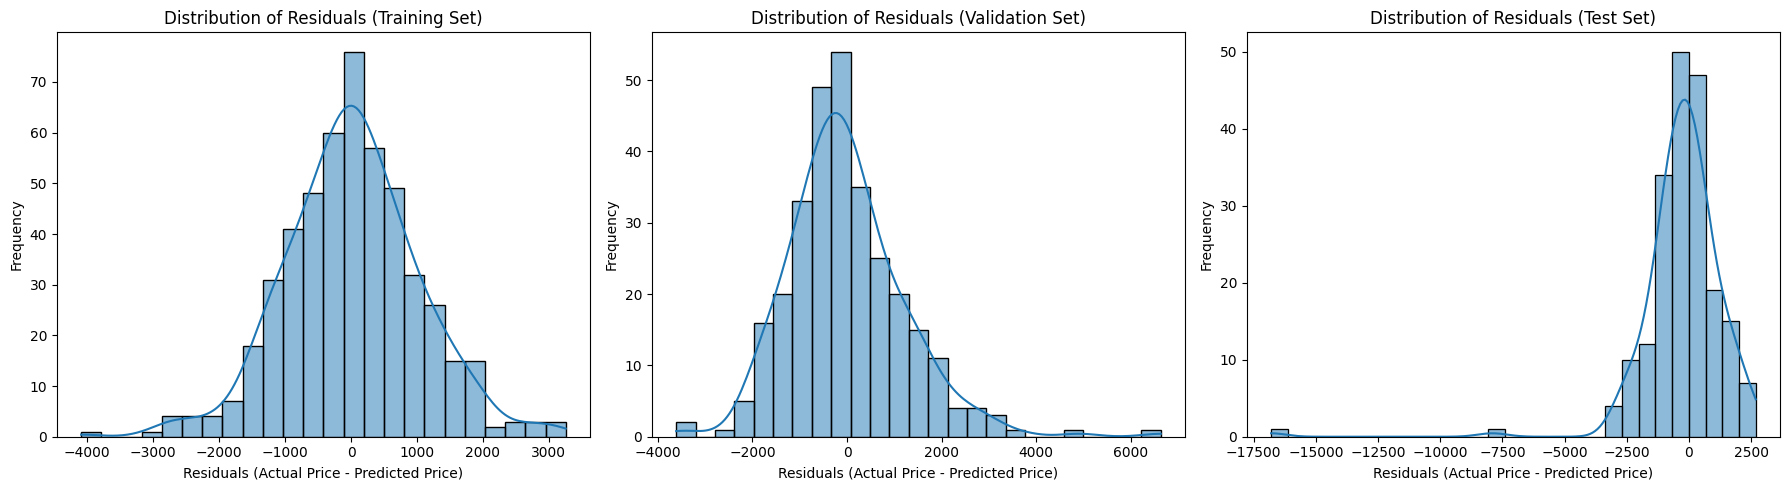


Summary Statistics of Residuals (Training Set):
count     500.000000
mean       17.144662
std      1022.578319
min     -4093.873751
25%      -607.476809
50%        -7.586540
75%       633.583534
max      3257.515747
Name: Price, dtype: float64

Summary Statistics of Residuals (Validation Set):
count     300.000000
mean      -15.105382
std      1238.044357
min     -3611.601112
25%      -807.344198
50%      -142.333091
75%       592.985290
max      6630.289216
Name: Price, dtype: float64

Summary Statistics of Residuals (Test Set):
count      200.000000
mean      -257.740853
std       1735.427714
min     -16798.229913
25%       -890.960122
50%       -161.428853
75%        519.977010
max       2685.003349
Name: Price, dtype: float64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals for all three sets
residuals_train = y_train - y_pred_train
residuals_val = y_val - y_pred_val
residuals_test = y_test - y_pred_test

# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 row, 3 columns

# Plot the distribution of residuals for the training set
sns.histplot(residuals_train, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Residuals (Training Set)')
axes[0].set_xlabel('Residuals (Actual Price - Predicted Price)')
axes[0].set_ylabel('Frequency')

# Plot the distribution of residuals for the validation set
sns.histplot(residuals_val, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Residuals (Validation Set)')
axes[1].set_xlabel('Residuals (Actual Price - Predicted Price)')
axes[1].set_ylabel('Frequency')

# Plot the distribution of residuals for the test set
sns.histplot(residuals_test, kde=True, ax=axes[2])
axes[2].set_title('Distribution of Residuals (Test Set)')
axes[2].set_xlabel('Residuals (Actual Price - Predicted Price)')
axes[2].set_ylabel('Frequency')

# Adjust layout to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

# Also display summary statistics of residuals for all three sets
print("\nSummary Statistics of Residuals (Training Set):")
print(residuals_train.describe())

print("\nSummary Statistics of Residuals (Validation Set):")
print(residuals_val.describe())

print("\nSummary Statistics of Residuals (Test Set):")
print(residuals_test.describe())

And the actual by predicted plots.  Both these and the residuals show one car in Test where the prediction was very far off.  This is probably skewing our results.  

Interpretation of Residual Summary Statistics
The residual statistics help us understand how accurately the Neural Network predicts car prices and whether it tends to overpredict or underpredict.

1. Training Set
- The mean residual is 17.14, which is close to zero, indicating very little average prediction bias.
- The median residual is -7.59, also close to zero.
- Residuals range from -4,093.87 to 3,257.52, showing that some predictions have relatively large errors.
2. Validation Set
- The mean residual is -15.11, indicating a slight tendency to overpredict prices on average.
- The median residual is -142.33.
- The maximum residual is 6,630.29, suggesting that the model significantly underpredicted some car prices.
3. Test Set
- The mean residual is -257.74, indicating a tendency to overpredict car prices on average.
- The standard deviation increases to 1,735.43, showing greater variation in prediction errors.
- The minimum residual of -16,798.23 indicates a substantial overprediction for at least one observation.


**Overall observation**


The training and validation residuals are reasonably centered around zero. However, the test residuals show greater variability and a more negative average, suggesting that the model does not generalize as consistently to unseen data. There are also some large residuals across all three datasets, indicating that the model struggles to predict certain car prices accurately.

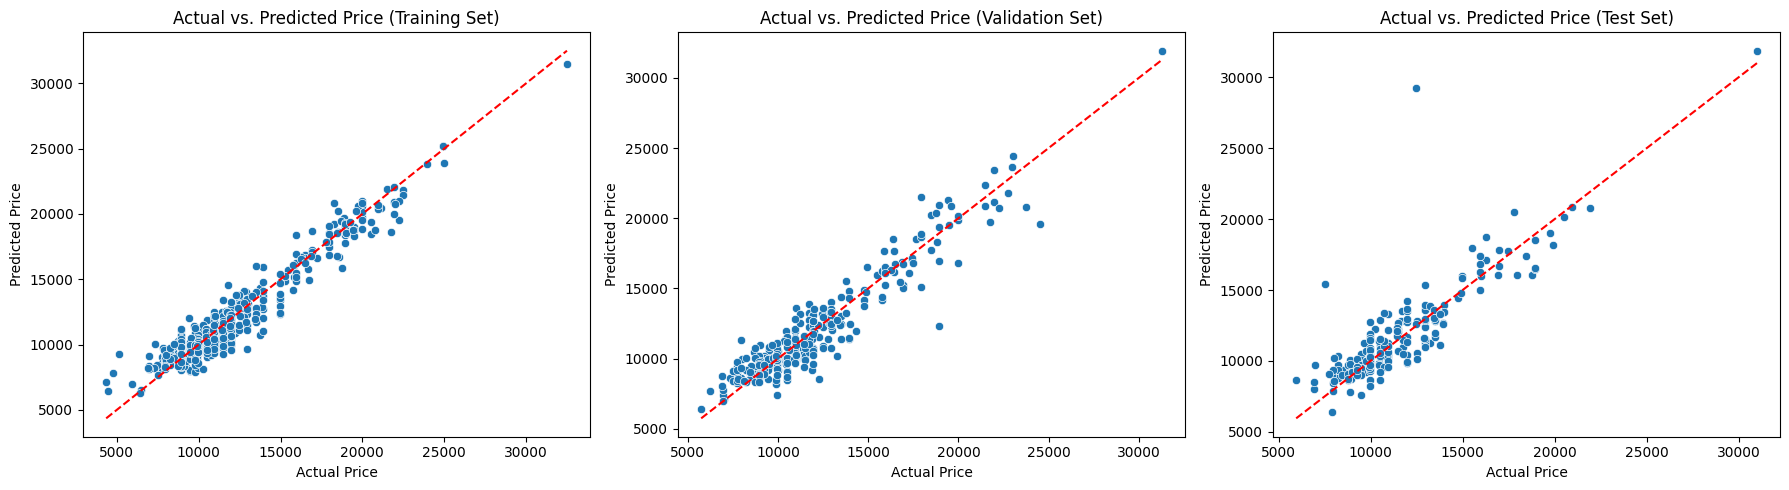

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 row, 3 columns

# Plot actual vs. predicted for the training set
sns.scatterplot(x=y_train, y=y_pred_train, ax=axes[0])
axes[0].set_title('Actual vs. Predicted Price (Training Set)')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--') # Add a diagonal line

# Plot actual vs. predicted for the validation set
sns.scatterplot(x=y_val, y=y_pred_val, ax=axes[1])
axes[1].set_title('Actual vs. Predicted Price (Validation Set)')
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--') # Add a diagonal line


# Plot actual vs. predicted for the test set
sns.scatterplot(x=y_test, y=y_pred_test, ax=axes[2])
axes[2].set_title('Actual vs. Predicted Price (Test Set)')
axes[2].set_xlabel('Actual Price')
axes[2].set_ylabel('Predicted Price')
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--') # Add a diagonal line


# Adjust layout to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

#Ensemble Models

In order to form an ensemble model, we need at least two models to combine.  So let's build a simple linear regression to combine with our NN model.

In [11]:
from sklearn.linear_model import LinearRegression

# Define the features for the linear regression model
linear_features = ['Age', 'Mileage', 'Horse Power', 'Weight']

# Create and train the linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train[linear_features], y_train)

# Print the coefficients
print("Linear Regression Model Coefficients:")
for feature, coef in zip(linear_features, lr_model.coef_):
    print(f"  {feature}: {coef:.2f}")
print(f"  Intercept: {lr_model.intercept_:.2f}")

Linear Regression Model Coefficients:
  Age: -128.24
  Mileage: -0.02
  Horse Power: 42.21
  Weight: 20.01
  Intercept: -6423.94


Observation
- Age has a negative relationship with car price, suggesting older cars generally have lower prices.
- Mileage also has a negative relationship, meaning cars driven more tend to have lower prices.
- Horse Power and Weight have positive coefficients, indicating positive relationships with predicted price in this model.

Now let's check its performance.

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

# Make predictions on all three sets using the linear regression model
y_pred_train_lr = lr_model.predict(X_train[linear_features])
y_pred_val_lr = lr_model.predict(X_val[linear_features])
y_pred_test_lr = lr_model.predict(X_test[linear_features])

# Evaluate performance on the training set
rmse_train_lr = np.sqrt(mean_squared_error(y_train, y_pred_train_lr))
r2_train_lr = r2_score(y_train, y_pred_train_lr)

# Evaluate performance on the validation set
rmse_val_lr = np.sqrt(mean_squared_error(y_val, y_pred_val_lr))
r2_val_lr = r2_score(y_val, y_pred_val_lr)

# Evaluate performance on the test set
rmse_test_lr = np.sqrt(mean_squared_error(y_test, y_pred_test_lr))
r2_test_lr = r2_score(y_test, y_pred_test_lr)

# Print the results
print("Linear Regression Model Performance:")
print(f"  Training Set: RMSE = {rmse_train_lr:.2f}, R-squared = {r2_train_lr:.2f}")
print(f"  Validation Set: RMSE = {rmse_val_lr:.2f}, R-squared = {r2_val_lr:.2f}")
print(f"  Test Set: RMSE = {rmse_test_lr:.2f}, R-squared = {r2_test_lr:.2f}")

Linear Regression Model Performance:
  Training Set: RMSE = 1369.66, R-squared = 0.87
  Validation Set: RMSE = 1307.70, R-squared = 0.88
  Test Set: RMSE = 1629.88, R-squared = 0.75


Observations:
1. Training performance: The model achieved an R-squared of 0.87, explaining 87% of the variation in car prices.
2. Validation performance: The R-squared increased slightly to 0.88, with an RMSE of 1,307.70, indicating strong predictive performance on the validation dataset.
3. Test performance: The R-squared decreased to 0.75, while RMSE increased to 1,629.88, indicating reduced prediction accuracy on unseen test data.
4. Generalization: The training and validation results are relatively consistent, suggesting limited evidence of overfitting. However, the decline in test performance indicates that the model may not generalize equally well to all unseen observations.

Now that we have two models, we can do simple model averaging to form a new ensemble model.

In [13]:
# Average the predictions from the two models
y_pred_train_ensemble = (y_pred_train + y_pred_train_lr) / 2
y_pred_val_ensemble = (y_pred_val + y_pred_val_lr) / 2
y_pred_test_ensemble = (y_pred_test + y_pred_test_lr) / 2

# Evaluate the ensemble model on the training set
rmse_train_ensemble = np.sqrt(mean_squared_error(y_train, y_pred_train_ensemble))
r2_train_ensemble = r2_score(y_train, y_pred_train_ensemble)

# Evaluate the ensemble model on the validation set
rmse_val_ensemble = np.sqrt(mean_squared_error(y_val, y_pred_val_ensemble))
r2_val_ensemble = r2_score(y_val, y_pred_val_ensemble)

# Evaluate the ensemble model on the test set
rmse_test_ensemble = np.sqrt(mean_squared_error(y_test, y_pred_test_ensemble))
r2_test_ensemble = r2_score(y_test, y_pred_test_ensemble)

# Print the results
print("Ensemble Model Performance (Averaging):")
print(f"  Training Set: RMSE = {rmse_train_ensemble:.2f}, R-squared = {r2_train_ensemble:.2f}")
print(f"  Validation Set: RMSE = {rmse_val_ensemble:.2f}, R-squared = {r2_val_ensemble:.2f}")
print(f"  Test Set: RMSE = {rmse_test_ensemble:.2f}, R-squared = {r2_test_ensemble:.2f}")

Ensemble Model Performance (Averaging):
  Training Set: RMSE = 1132.61, R-squared = 0.91
  Validation Set: RMSE = 1211.04, R-squared = 0.90
  Test Set: RMSE = 1630.88, R-squared = 0.75


Observations:
1. Training performance: The model achieved an R-squared of 0.91, explaining 91% of the variation in car prices.
2. Validation performance: The R-squared of 0.90 indicates strong predictive performance, with an RMSE of 1,211.04.
3. Test performance: The R-squared decreased to 0.75, and RMSE increased to 1,630.88, indicating some reduction in accuracy on unseen data.
4. Generalization: Training and validation results are very close, suggesting that the ensemble does not show significant overfitting between these two datasets. However, its test performance is weaker.

We could scroll up and down through the notebook to compare results, but a single model comparison table is much better.

In [15]:
# Create a dictionary to store the performance metrics
performance_data = {
    'Model': ['Neural Network', 'Linear Regression', 'Ensemble (Averaging)'],
    'Train RMSE': [rmse_train, rmse_train_lr, rmse_train_ensemble],
    'Train R-squared': [r2_train, r2_train_lr, r2_train_ensemble],
    'Validation RMSE': [rmse_val, rmse_val_lr, rmse_val_ensemble],
    'Validation R-squared': [r2_val, r2_val_lr, r2_val_ensemble],
    'Test RMSE': [rmse_test, rmse_test_lr, rmse_test_ensemble],
    'Test R-squared': [r2_test, r2_test_lr, r2_test_ensemble]
}

# Create a pandas DataFrame from the dictionary
performance_df = pd.DataFrame(performance_data)

# Display the DataFrame
print("Model Performance Comparison:")
display(performance_df.round(2))

Model Performance Comparison:


,Model,Train RMSE,Train R-squared,Validation RMSE,Validation R-squared,Test RMSE,Test R-squared
0,Neural Network,1021.70,0.93,1236.07,0.90,1750.17,0.71
1,Linear Regression,1369.66,0.87,1307.70,0.88,1629.88,0.75
2,Ensemble (Averaging),1132.61,0.91,1211.04,0.90,1630.88,0.75


Overall Performance and Recommendation
The results indicate that all three models explain a substantial proportion of the variation in car prices, with test R-squared values ranging from 0.71 to 0.75.
- The Neural Network performs best on training data but shows signs of overfitting.
- The Ensemble performs best on validation data, suggesting strong predictive capability during model evaluation.
- Linear Regression delivers the best test performance, although its advantage over the Ensemble is very small.

We can see that the ensemble outperforms the linear regression, but doesn't beat the NN.  So NN is the best!